# PCA coordinate fix: visual and quantitative check

This notebook tests the fix to SONG's 51–100 feature PCA path on the same 600 digit samples used in the baseline report. It compares the corrected default (`pc_components=50`, 11 dispersion epochs), a 100-epoch quality setting, the no-PCA path (`pc_components=64`), and standalone UMAP across five seeds. The historical pre-fix measurements in `tuning_sweep.csv` are a single-seed reference, not a paired five-seed run. Timing excludes a JIT warm-up and includes fit plus transform; budgets differ between SONG and standalone UMAP.

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from umap import UMAP
from song.song import SONG

fig_dir = Path('reports/figures'); fig_dir.mkdir(parents=True, exist_ok=True)
digits = load_digits()
indices = np.random.default_rng(42).permutation(len(digits.data))[:600]
X = (digits.data[indices] / 16).astype(np.float32)
labels = digits.target[indices]
SONG(so_steps=2, final_vector_count=16, dispersion_method='none').fit_transform(X[:80])
SONG(so_steps=2, final_vector_count=16, dispersion_method='UMAP').fit_transform(X[:80])
UMAP(random_state=42).fit_transform(X[:80])
print('N=',len(X),'D=',X.shape[1],'threads=',os.environ.get('NUMBA_NUM_THREADS','default'))

/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


N= 600 D= 64 threads= 2


In [2]:
rows = []
embeddings = {}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for seed in [42, 43, 44, 45, 46]:
    for name, pc_components, um_epochs in [('SONG fixed PCA', 50, 11), ('SONG tuned dispersion', 50, 100), ('SONG no PCA', 64, 11), ('UMAP', None, None)]:
        np.random.seed(seed)
        start = time.perf_counter()
        if name == 'UMAP':
            Y = UMAP(random_state=seed).fit_transform(X)
        else:
            Y = SONG(random_seed=seed, so_steps=30, final_vector_count=48,
                     chunk_size=128, pc_components=pc_components, um_epochs=um_epochs,
                     dispersion_method='UMAP').fit_transform(X)
        elapsed = time.perf_counter() - start
        assert Y.shape == (len(X), 2) and np.isfinite(Y).all()
        clusters = KMeans(n_clusters=10, n_init=10, random_state=seed).fit_predict(Y)
        rows.append(dict(seed=seed, method=name, seconds=elapsed,
                         trustworthiness=trustworthiness(X, Y, n_neighbors=10),
                         kmeans_ARI=adjusted_rand_score(labels, clusters),
                         kmeans_AMI=adjusted_mutual_info_score(labels, clusters),
                         kNN_probe_accuracy=cross_val_score(
                             KNeighborsClassifier(n_neighbors=5), Y, labels, cv=cv).mean()))
        if seed == 42:
            embeddings[name] = Y.copy()
results = pd.DataFrame(rows)
results.to_csv('reports/pca_fix_validation.csv', index=False)
display(results.groupby('method')[['seconds','trustworthiness','kmeans_ARI','kmeans_AMI','kNN_probe_accuracy']].agg(['mean','std']).round(3))

/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


seconds        trustworthiness        kmeans_ARI         \
                         mean    std            mean    std       mean    std   
method                                                                          
SONG fixed PCA          0.189  0.008           0.975  0.001      0.755  0.024   
SONG no PCA             0.186  0.002           0.977  0.001      0.805  0.036   
SONG tuned dispersion   0.229  0.012           0.983  0.002      0.815  0.042   
UMAP                    0.499  0.004           0.982  0.001      0.863  0.009   

                      kmeans_AMI        kNN_probe_accuracy         
                            mean    std               mean    std  
method                                                             
SONG fixed PCA             0.818  0.016              0.940  0.013  
SONG no PCA                0.853  0.021              0.959  0.008  
SONG tuned dispersion      0.862  0.021              0.965  0.004  
UMAP                       0.902  0.004              0.979  0.004

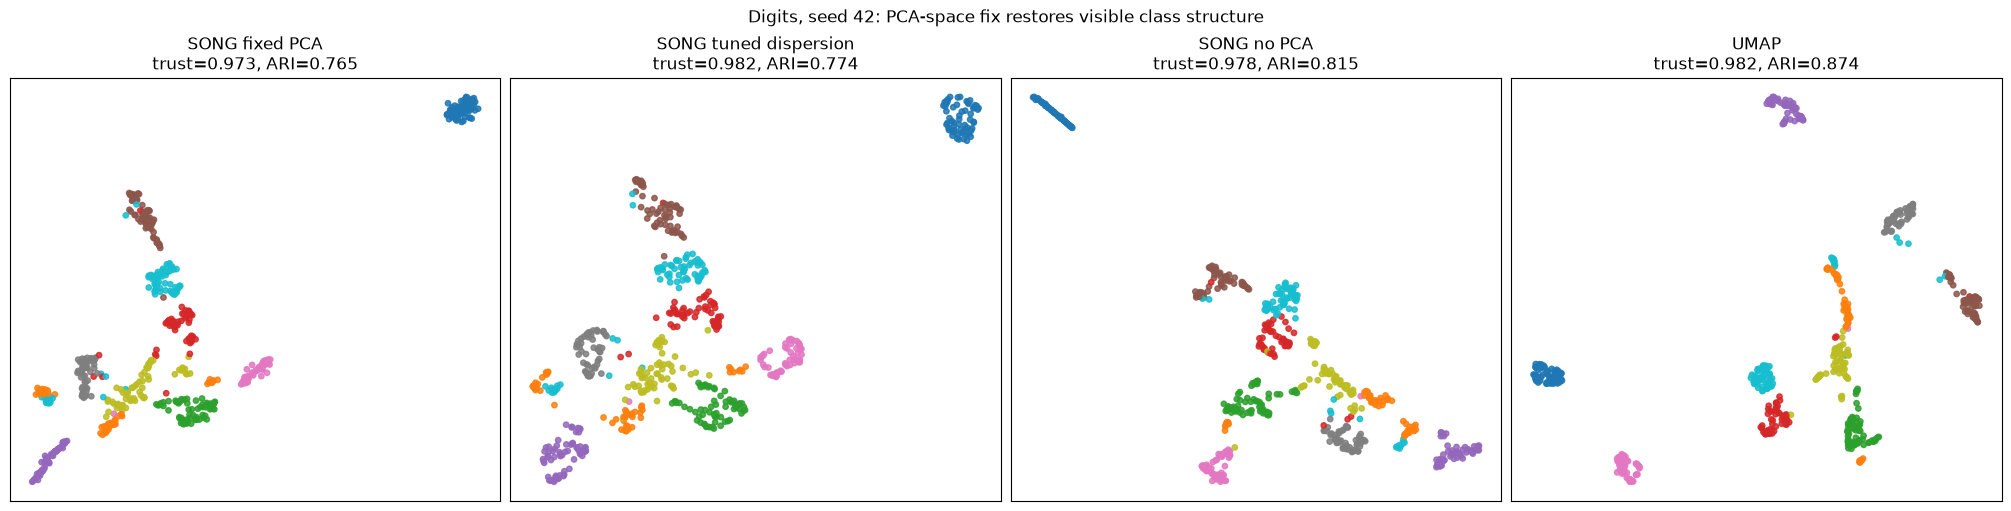

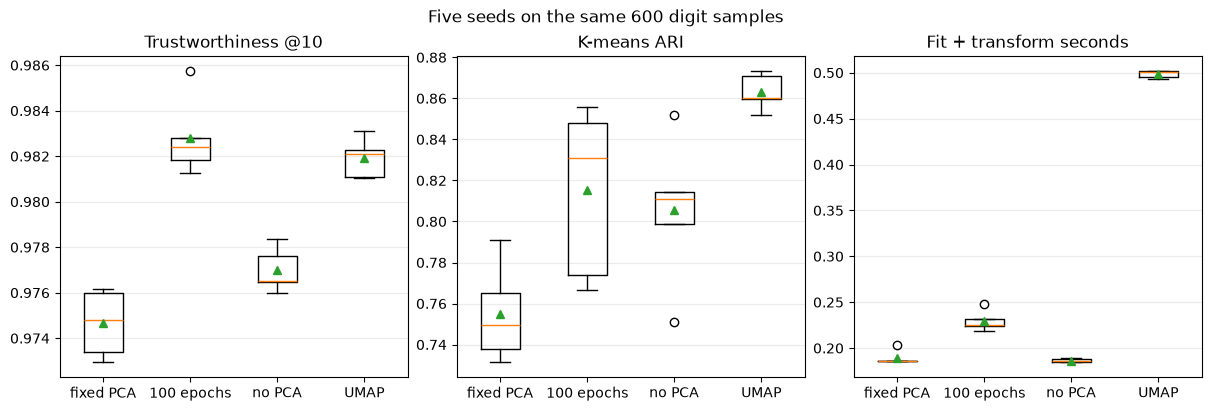

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for ax, name in zip(axes, ['SONG fixed PCA', 'SONG tuned dispersion', 'SONG no PCA', 'UMAP']):
    Y = embeddings[name]
    ax.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9,
               s=15, alpha=.85, rasterized=True)
    row = results[(results.seed == 42) & (results.method == name)].iloc[0]
    ax.set_title(f'{name}\ntrust={row.trustworthiness:.3f}, ARI={row.kmeans_ARI:.3f}')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Digits, seed 42: PCA-space fix restores visible class structure')
fig.savefig(fig_dir / 'pca_fix_embeddings.png', dpi=180)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, metric, title in zip(axes, ['trustworthiness','kmeans_ARI','seconds'],
                              ['Trustworthiness @10','K-means ARI','Fit + transform seconds']):
    data = [results.loc[results.method == name, metric].to_numpy()
            for name in ['SONG fixed PCA', 'SONG tuned dispersion', 'SONG no PCA', 'UMAP']]
    ax.boxplot(data, tick_labels=['fixed PCA','100 epochs','no PCA','UMAP'], showmeans=True)
    ax.set_title(title)
    ax.grid(axis='y', alpha=.25)
fig.suptitle('Five seeds on the same 600 digit samples')
fig.savefig(fig_dir / 'pca_fix_scores.png', dpi=180)
plt.show()

## Interpretation

The saved pre-fix `30 steps` run in `tuning_sweep.csv` had trustworthiness 0.853 and K-means ARI 0.303. The fix changes only how coding vectors are projected for nearest-prototype searches. The five-seed results above show whether corrected PCA reaches the no-PCA path consistently. The 2D scatter is useful for spotting fragmented or mixed digit groups, but the labels are evaluation data and are not used to fit the embeddings. The chart does not establish performance on the paper's MNIST or Fashion-MNIST datasets.

The 100-epoch row measures an explicit quality setting (`um_epochs=100`); the default remains 11 epochs to avoid a runtime increase for existing callers.